# Study 2: High-EDI policy feasibility

This experiment asks why episodes targeting EDI 80 to 100 fail in the high-emissions candidates. Are the equations unable to support those development levels, or do the fixed policies fail to manage development, cash, and mitigation together?

The earlier development audit found that, under source emissions, the policy that developed to EDI 80 and then used high prevention survived all 100 tested seeds. The same strategy using medium prevention failed all 100. The equation-balance experiment tested EDI 80 to 100 at emissions multipliers 3.10 to 3.20, where all tested policies failed. These findings suggest that failure depends on both policy and emissions pressure. This notebook separates growth from maintenance and tests additional transparent fixed policies against the unchanged Study 2 environment.

No agents are trained. The environment source, rewards, and base configuration are left unchanged. Stress scenarios use fresh configuration objects in this notebook.

## 1. How this experiment separates policy limits from environment limits

1. Compare fixed policies from identical seeds and initial currency draws while targeting EDI 80 and 100.
2. Test source emissions and progressively higher EDI-linked emissions, including multiplier 3.12.
3. Compare policies that develop first and mitigate later, develop while mitigating, and switch between prevention and cleanup based on observed pollution pressure.
4. Hold EDI fixed at 80 or 100 with ample cash. This maintenance probe removes development costs and limited starting cash; it asks whether the environment can sustain the target once reached.
5. Inspect action fallbacks, spending, pollution by pollutant, failure timing, and trajectories. A successful maintenance probe shows that the environment can support that fixed EDI under that policy and scenario. Failure under one probe does not prove that every possible policy must fail.

In [52]:
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from study_2_economic_sustainability.config import EnvironmentConfig
from study_2_economic_sustainability.environment import (ACTION_NAMES, EconomicSustainabilityEnvironment, action_parts)

In [53]:
BASE_CONFIG = EnvironmentConfig()
POLLUTANTS = BASE_CONFIG.pollutants
REGIONS = BASE_CONFIG.regions
SEEDS = tuple(range(40_000, 40_050))
TARGETS = (80, 100)
EMISSION_MULTIPLIERS = (1.0, 1.5, 2.0, 3.1, 3.12, 3.2)

ACTION_IDS = {}
for action_id, action_name in enumerate(ACTION_NAMES):
    ACTION_IDS[action_name] = action_id

print(f"Shared seeds: {len(SEEDS)}")
print(f"Episode limit: {BASE_CONFIG.episode_steps}")
print(f"Targets: {TARGETS}")
print(f"Emission multipliers: {EMISSION_MULTIPLIERS}")
print(f"Pollution limits: {BASE_CONFIG.pollution_limits}")

Shared seeds: 50
Episode limit: 200
Targets: (80, 100)
Emission multipliers: (1.0, 1.5, 2.0, 3.1, 3.12, 3.2)
Pollution limits: {'air': 100.0, 'water': 100.0, 'soil': 100.0, 'noise': 100.0}


## 2. Calculate the development and mitigation budget near the targets

The environment uses linear income and emissions. Development and mitigation are paid from the region's starting balance before the current step's income is credited. The table compares income with high-prevention and high-cleanup costs, both alone and when paired with development. The emissions multiplier scales only the EDI-linked emissions component; baseline emissions still occur.

In [54]:
def make_experiment_config(emission_multiplier=1.0, starting_cash_range=None):
    config = EnvironmentConfig()
    config.edi_emissions_per_point = {pollutant: config.edi_emissions_per_point[pollutant] * emission_multiplier for pollutant in config.pollutants}

    if starting_cash_range is not None:
        config.initial_currency_minimum = starting_cash_range[0]
        config.initial_currency_maximum = starting_cash_range[1]

    return config

In [55]:
budget_rows = []
for edi, multiplier in product((60, 70, 80, 90, 100), (1.0, 3.12)):
    income = BASE_CONFIG.income_base + BASE_CONFIG.income_per_edi * edi
    gross_emissions = {}

    for pollutant in POLLUTANTS:
        gross_emissions[pollutant] = (BASE_CONFIG.baseline_emissions[pollutant] + BASE_CONFIG.edi_emissions_per_point[pollutant] * edi * multiplier)

    total_gross_emissions = sum(gross_emissions.values())
    prevention_cost = BASE_CONFIG.prevention_costs[3]
    prevention_fraction = BASE_CONFIG.prevention_fractions[3]
    cleanup_cost = BASE_CONFIG.cleanup_costs[3]
    cleanup_capacity = BASE_CONFIG.cleanup_capacities[3]
    development_cost = BASE_CONFIG.development_cost

    budget_rows.append({
        "EDI": edi,
        "emissions multiplier": multiplier,
        "income / region / step": income,
        "gross emissions / region / step": total_gross_emissions,
        "gross emissions by pollutant": gross_emissions,
        "high prevention cost": prevention_cost,
        "remaining new emissions after high prevention": (total_gross_emissions * (1 - prevention_fraction)),
        "income less high prevention": income - prevention_cost,
        "income less development + high prevention": (income - development_cost - prevention_cost),
        "high cleanup cost": cleanup_cost,
        "cleanup capacity / pollutant": cleanup_capacity,
        "income less high cleanup": income - cleanup_cost,
        "income less development + high cleanup": (income - development_cost - cleanup_cost)
    })

In [56]:
budget_table = pd.DataFrame(budget_rows)
display(budget_table.round(2))

,EDI,emissions multiplier,income / region / step,gross emissions / region / step,gross emissions by pollutant,high prevention cost,remaining new emissions after high prevention,income less high prevention,income less development + high prevention,high cleanup cost,cleanup capacity / pollutant,income less high cleanup,income less development + high cleanup
0,60,1.00,50.0,16.70,"{'air': 7.8, 'water': 3.4, 'soil': 1.7, 'noise...",50.0,4.18,0.0,-100.0,80.0,10.0,-30.0,-130.0
1,60,3.12,50.0,38.32,"{'air': 17.976, 'water': 8.488, 'soil': 4.244,...",50.0,9.58,0.0,-100.0,80.0,10.0,-30.0,-130.0
2,70,1.00,55.0,18.40,"{'air': 8.600000000000001, 'water': 3.80000000...",50.0,4.60,5.0,-95.0,80.0,10.0,-25.0,-125.0
3,70,3.12,55.0,43.63,"{'air': 20.472, 'water': 9.736, 'soil': 4.868,...",50.0,10.91,5.0,-95.0,80.0,10.0,-25.0,-125.0
4,80,1.00,60.0,20.10,"{'air': 9.4, 'water': 4.2, 'soil': 2.1, 'noise...",50.0,5.03,10.0,-90.0,80.0,10.0,-20.0,-120.0
5,80,3.12,60.0,48.93,"{'air': 22.968000000000004, 'water': 10.984000...",50.0,12.23,10.0,-90.0,80.0,10.0,-20.0,-120.0
6,90,1.00,65.0,21.80,"{'air': 10.2, 'water': 4.6, 'soil': 2.3, 'nois...",50.0,5.45,15.0,-85.0,80.0,10.0,-15.0,-115.0
7,90,3.12,65.0,54.24,"{'air': 25.464000000000002, 'water': 12.232000...",50.0,13.56,15.0,-85.0,80.0,10.0,-15.0,-115.0
8,100,1.00,70.0,23.50,"{'air': 11.0, 'water': 5.0, 'soil': 2.5, 'nois...",50.0,5.88,20.0,-80.0,80.0,10.0,-10.0,-110.0
9,100,3.12,70.0,59.54,"{'air': 27.96, 'water': 13.48, 'soil': 6.74, '...",50.0,14.88,20.0,-80.0,80.0,10.0,-10.0,-110.0


### What the budget table implies

At EDI 80, current income is 60 per region per step; at EDI 100 it is 70. High prevention costs 50, while high cleanup costs 80. During development, combining high prevention with the 100 development cost costs 150 per step, and combining high cleanup with development costs 180. Those combinations run a cash deficit at EDI 80 to 100 even though high prevention alone has a positive income margin after the target is reached. The policy therefore has to manage timing and liquidity, not only long-run average income.

High prevention reduces new emissions but does not remove existing pollution stock. High cleanup removes stock but does not reduce that step's emissions. The one-investment-per-region action rule prevents applying both at once.

## 3. Define comparable non-learning policies

All target policies use the same environment step function and the same seeded initial currency draws. They differ only in their explicit action rule. The adaptive policies use current regional pollution pressure, defined as load divided by its pollutant limit, to switch between high prevention and high cleanup. If a proposed action is unaffordable, the runner records the fallback and selects the first affordable alternative from a fixed order.

In [57]:
def action_cost(action_name, config):
    action_id = ACTION_IDS[action_name]
    development_choice, investment_choice = action_parts(action_id)
    cost = config.development_cost if development_choice else 0.0

    if investment_choice in (1, 2, 3):
        cost += config.prevention_costs[investment_choice]
    elif investment_choice in (4, 5, 6):
        cleanup_level = investment_choice - 3
        cost += config.cleanup_costs[cleanup_level]

    return cost

In [58]:
def action_is_affordable(action_name, balance, edi, config):
    action_id = ACTION_IDS[action_name]
    development_choice, investment_choice = action_parts(action_id)
    can_develop = not development_choice or edi < 100
    return can_develop and balance >= action_cost(action_name, config)

In [59]:
def pollution_pressure(environment, region):
    pressure = 0.0

    for pollutant in environment.config.pollutants:
        load = environment.pollutant_loads[pollutant][region]
        limit = environment.config.pollution_limits[pollutant]
        pressure = max(pressure, load / limit)

    return pressure

In [60]:
def choose_affordable_action(preferred_action, balance, edi, config):
    if preferred_action.startswith("develop_"):
        fallback_order = [
            preferred_action,
            "develop_none",
            "develop_prevent_high",
            "develop_clean_high",
            "maintain_prevent_high",
            "maintain_clean_high",
            "maintain_none",
        ]
    else:
        fallback_order = [
            preferred_action,
            "maintain_prevent_high",
            "maintain_clean_high",
            "maintain_prevent_medium",
            "maintain_clean_medium",
            "maintain_prevent_low",
            "maintain_clean_low",
            "maintain_none",
        ]

    for action_name in dict.fromkeys(fallback_order):
        if action_is_affordable(action_name, balance, edi, config):
            return action_name

    return "maintain_none"

In [61]:
def choose_policy_actions(policy_name, environment, target):
    rule = ALL_RULES[policy_name]
    kind = rule["kind"]

    proposed_actions = []
    executed_actions = []
    fallback_count = 0

    for region in REGIONS:
        edi = environment.development_indices[region]
        balance = environment.currency_balances[region]
        pressure = pollution_pressure(environment, region)
        developing = edi < target

        if kind == "fixed":
            preferred = rule["action"]

        elif kind == "sequential":
            preferred = "maintain_prevent_high"

            if developing:
                preferred = "develop_none"

        elif kind in ("simultaneous_prevention", "simultaneous_cleanup"):
            investment = "prevent_high"

            if kind == "simultaneous_cleanup":
                investment = "clean_high"

            activity = "maintain"

            if developing:
                activity = "develop"

            preferred = f"{activity}_{investment}"

        else:
            threshold = rule["threshold"]
            investment = "prevent_high"

            if pressure >= threshold:
                investment = "clean_high"

            activity = "maintain"

            if developing:
                activity = "develop"

            preferred = f"{activity}_{investment}"

            if kind == "cash_guard_adaptive" and developing:
                required_cash = action_cost(preferred, environment.config)
                required_cash += rule["reserve"]

                if balance < environment.config.development_cost:
                    preferred = "maintain_prevent_high"

                elif balance < required_cash:
                    preferred = "develop_none"

        if kind == "sequential" and not action_is_affordable(preferred, balance, edi, environment.config):
            executed = "maintain_none"
        else:
            executed = choose_affordable_action(preferred, balance, edi, environment.config)

        proposed_actions.append(ACTION_IDS[preferred])
        executed_actions.append(ACTION_IDS[executed])
        fallback_count += executed != preferred

    return proposed_actions, executed_actions, fallback_count

In [62]:
def run_policy_episode(policy_name, seed, config, target, initial_state=None, save_trace=False):
    environment = EconomicSustainabilityEnvironment(config=config)
    environment.reset(seed)

    if initial_state is not None:
        environment.development_indices = tuple(initial_state["edi"] for _ in REGIONS)
        environment.currency_balances = tuple(initial_state["currency"] for _ in REGIONS)
        environment.pollutant_loads = {pollutant: tuple(initial_state["pollution"] for _ in REGIONS) for pollutant in POLLUTANTS}
        environment._update_indices()

    initial_currency = list(environment.currency_balances)
    income_total = 0.0
    spending_total = 0.0
    development_spending = 0.0
    prevention_spending = 0.0
    cleanup_spending = 0.0
    fallback_count = 0
    invalid_actions = 0
    target_reached_step = np.nan
    peak_pollution = {pollutant: max(environment.pollutant_loads[pollutant]) for pollutant in POLLUTANTS}
    peak_pressure = max(pollution_pressure(environment, region) for region in REGIONS)
    failure_pollutants = ()
    trajectory = []
    action_counts = {action_name: 0 for action_name in ACTION_NAMES}

    for step in range(1, config.episode_steps + 1):
        proposed_actions, executed_actions, step_fallbacks = choose_policy_actions(policy_name, environment, target)
        result = environment.step(executed_actions)
        _, _, terminated, truncated, info = result
        fallback_count += step_fallbacks
        invalid_actions += sum(info["invalid_attempts"])
        income_total += sum(info["income"])
        spending_total += sum(info["costs_paid"])
        development_spending += sum(info["development_costs_paid"])
        prevention_spending += sum(info["prevention_costs_paid"])
        cleanup_spending += sum(info["cleanup_costs_paid"])

        for action_name in info["action_names"]:
            action_counts[action_name] += 1

        all_regions_reached = min(environment.development_indices) >= target
        if all_regions_reached and np.isnan(target_reached_step):
            target_reached_step = step

        for pollutant in POLLUTANTS:
            peak_pollution[pollutant] = max(peak_pollution[pollutant], max(info["pollutant_loads"][pollutant]))

        step_pressure = 0.0
        for region in REGIONS:
            step_pressure = max(step_pressure, pollution_pressure(environment, region))
        peak_pressure = max(peak_pressure, step_pressure)

        if terminated:
            failure_pollutants = tuple(sorted({pollutant for _, pollutant in info["failed_regions"]}))

        if save_trace:
            for region in REGIONS:
                row = {
                    "step": step,
                    "region": region,
                    "proposed_action": ACTION_NAMES[proposed_actions[region]],
                    "executed_action": info["action_names"][region],
                    "edi": environment.development_indices[region],
                    "currency": environment.currency_balances[region],
                    "income": info["income"][region],
                    "spending": info["costs_paid"][region],
                    "development_spending": info["development_costs_paid"][region],
                    "pressure": pollution_pressure(environment, region),
                    "failed_this_step": terminated,
                }
                for pollutant in POLLUTANTS:
                    row[pollutant] = info["pollutant_loads"][pollutant][region]
                trajectory.append(row)

        if terminated or truncated:
            break

    final_mean_edi = float(np.mean(environment.development_indices))
    reached_target = min(environment.development_indices) >= target
    row = {
        "policy": policy_name,
        "target": target,
        "seed": seed,
        "steps": environment.step_count,
        "failed": terminated,
        "survived": not terminated,
        "reached_target": reached_target,
        "success": not terminated and reached_target,
        "target_reached_step": target_reached_step,
        "failure_pollutants": ", ".join(failure_pollutants),
        "final_mean_edi": final_mean_edi,
        "final_min_edi": min(environment.development_indices),
        "final_mean_currency": float(np.mean(environment.currency_balances)),
        "mean_initial_currency": float(np.mean(initial_currency)),
        "income": income_total,
        "spending": spending_total,
        "development_spending": development_spending,
        "prevention_spending": prevention_spending,
        "cleanup_spending": cleanup_spending,
        "fallback_count": fallback_count,
        "action_counts": action_counts,
        "invalid_actions": invalid_actions,
        "peak_pressure": peak_pressure,
        **{f"peak_{pollutant}": peak_pollution[pollutant] for pollutant in POLLUTANTS},
        "failure_step": environment.step_count if terminated else np.nan,
    }

    if save_trace:
        row["trajectory"] = trajectory

    return row

In [63]:
POLICY_RULES = {
    "develop_then_prevent_high": {"kind": "sequential"},
    "develop_with_prevention_high": {"kind": "simultaneous_prevention"},
    "develop_with_cleanup_high": {"kind": "simultaneous_cleanup"},
    "adaptive_threshold_0.25": {"kind": "adaptive", "threshold": 0.25},
    "adaptive_threshold_0.50": {"kind": "adaptive", "threshold": 0.50},
    "adaptive_threshold_0.75": {"kind": "adaptive", "threshold": 0.75},
    "cash_guard_250_adaptive_0.50": {
        "kind": "cash_guard_adaptive", "threshold": 0.50, "reserve": 250
    },
}

MAINTENANCE_RULES = {
    "maintain_prevent_high": {"kind": "fixed", "action": "maintain_prevent_high"},
    "maintain_clean_high": {"kind": "fixed", "action": "maintain_clean_high"},
    "maintenance_adaptive_0.25": {"kind": "maintenance_adaptive", "threshold": 0.25},
    "maintenance_adaptive_0.50": {"kind": "maintenance_adaptive", "threshold": 0.50},
    "maintenance_adaptive_0.75": {"kind": "maintenance_adaptive", "threshold": 0.75},
}
ALL_RULES = {**POLICY_RULES, **MAINTENANCE_RULES}

## 4. Test target attainment across emissions pressure and policies

This is the main policy-versus-environment comparison. The 50 shared seeds give every policy the same starting regional balances within each scenario. A target counts as reached only if all four regions attain it; success additionally requires surviving the full 200 steps. Fallback counts show when the preferred development and mitigation combination was unaffordable and another action was used.

In [64]:
target_rows = []

for multiplier in EMISSION_MULTIPLIERS:
    config = make_experiment_config(multiplier)

    for target in TARGETS:
        for policy_name in POLICY_RULES:
            for seed in SEEDS:
                episode = run_policy_episode(policy_name, seed, config, target)
                episode["emission_multiplier"] = multiplier
                target_rows.append(episode)

target_results = pd.DataFrame(target_rows)

target_summary = target_results.groupby(["target", "policy", "emission_multiplier"]).agg(
    episodes=("success", "size"),
    success_rate=("success", "mean"),
    survival_rate=("survived", "mean"),
    target_reached_rate=("reached_target", "mean"),
    mean_final_edi=("final_mean_edi", "mean"),
    mean_failure_step=("failure_step", "mean"),
    mean_income=("income", "mean"),
    mean_development_spending=("development_spending", "mean"),
    mean_prevention_spending=("prevention_spending", "mean"),
    mean_cleanup_spending=("cleanup_spending", "mean"),
    mean_fallback_count=("fallback_count", "mean"),
    mean_peak_pressure=("peak_pressure", "mean"),
    mean_peak_air=("peak_air", "mean"),
    mean_peak_water=("peak_water", "mean"),
    mean_peak_soil=("peak_soil", "mean"),
    mean_peak_noise=("peak_noise", "mean"),
).reset_index()

display(target_summary.round(3))

,target,policy,emission_multiplier,episodes,success_rate,survival_rate,target_reached_rate,mean_final_edi,mean_failure_step,mean_income,mean_development_spending,mean_prevention_spending,mean_cleanup_spending,mean_fallback_count,mean_peak_pressure,mean_peak_air,mean_peak_water,mean_peak_soil,mean_peak_noise
0,80,adaptive_threshold_0.25,1.00,50,0.0,1.00,0.0,37.675,NaN,30854.40,1742.0,31103.0,0.0,784.26,0.307,10.000,10.053,30.667,10.0
1,80,adaptive_threshold_0.25,1.50,50,0.0,1.00,0.0,37.675,NaN,30854.40,1742.0,31103.0,0.0,784.26,0.431,10.110,12.594,43.087,10.0
2,80,adaptive_threshold_0.25,2.00,50,0.0,1.00,0.0,37.675,NaN,30854.40,1742.0,31103.0,0.0,784.26,0.590,11.311,15.672,58.955,10.0
3,80,adaptive_threshold_0.25,3.10,50,0.0,0.14,0.0,37.675,166.070,26066.45,1742.0,26313.0,0.0,667.54,0.989,15.611,23.076,98.906,10.0
4,80,adaptive_threshold_0.25,3.12,50,0.0,0.12,0.0,37.675,165.341,25858.65,1742.0,26099.0,0.0,662.26,0.992,15.690,23.219,99.206,10.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,100,develop_with_prevention_high,1.50,50,0.0,1.00,0.0,37.675,NaN,30854.40,1742.0,31103.0,0.0,784.26,0.431,10.110,12.594,43.087,10.0
80,100,develop_with_prevention_high,2.00,50,0.0,1.00,0.0,37.675,NaN,30854.40,1742.0,31103.0,0.0,784.26,0.590,11.311,15.672,58.955,10.0
81,100,develop_with_prevention_high,3.10,50,0.0,0.14,0.0,37.675,166.070,26066.45,1742.0,26313.0,0.0,667.54,0.989,15.611,23.076,98.906,10.0
82,100,develop_with_prevention_high,3.12,50,0.0,0.12,0.0,37.675,165.341,25858.65,1742.0,26099.0,0.0,662.26,0.992,15.690,23.219,99.206,10.0


In [65]:
action_rows = []
for _, episode in target_results.iterrows():
    for action_name, count in episode["action_counts"].items():
        action_rows.append({
            "target": episode["target"],
            "policy": episode["policy"],
            "emission_multiplier": episode["emission_multiplier"],
            "action": action_name,
            "action_fraction": count / (len(REGIONS) * episode["steps"]),
        })

action_results = pd.DataFrame(action_rows)
action_summary = action_results.groupby(["target", "policy", "emission_multiplier", "action"])["action_fraction"].mean().reset_index()
display(action_summary.round(3))

,target,policy,emission_multiplier,action,action_fraction
0,80,adaptive_threshold_0.25,1.0,develop_clean_high,0.000
1,80,adaptive_threshold_0.25,1.0,develop_clean_low,0.000
2,80,adaptive_threshold_0.25,1.0,develop_clean_medium,0.000
3,80,adaptive_threshold_0.25,1.0,develop_none,0.002
4,80,adaptive_threshold_0.25,1.0,develop_prevent_high,0.020
...,...,...,...,...,...
1171,100,develop_with_prevention_high,3.2,maintain_clean_medium,0.000
1172,100,develop_with_prevention_high,3.2,maintain_none,0.220
1173,100,develop_with_prevention_high,3.2,maintain_prevent_high,0.753
1174,100,develop_with_prevention_high,3.2,maintain_prevent_low,0.000


### How to interpret the target sweep

Separate three outcomes: reaching the target, surviving to step 200, and achieving both. If a policy reaches EDI 100 and then fails during maintenance, that is evidence about sustainment. If it fails before reaching 80 or 100, inspect whether the failure was environmental, whether development was delayed by unaffordable actions, and which pollutant crossed its limit. Compare these outcomes at multiplier 1.0 with those at 3.1 to 3.2 before attributing failure to the base environment.

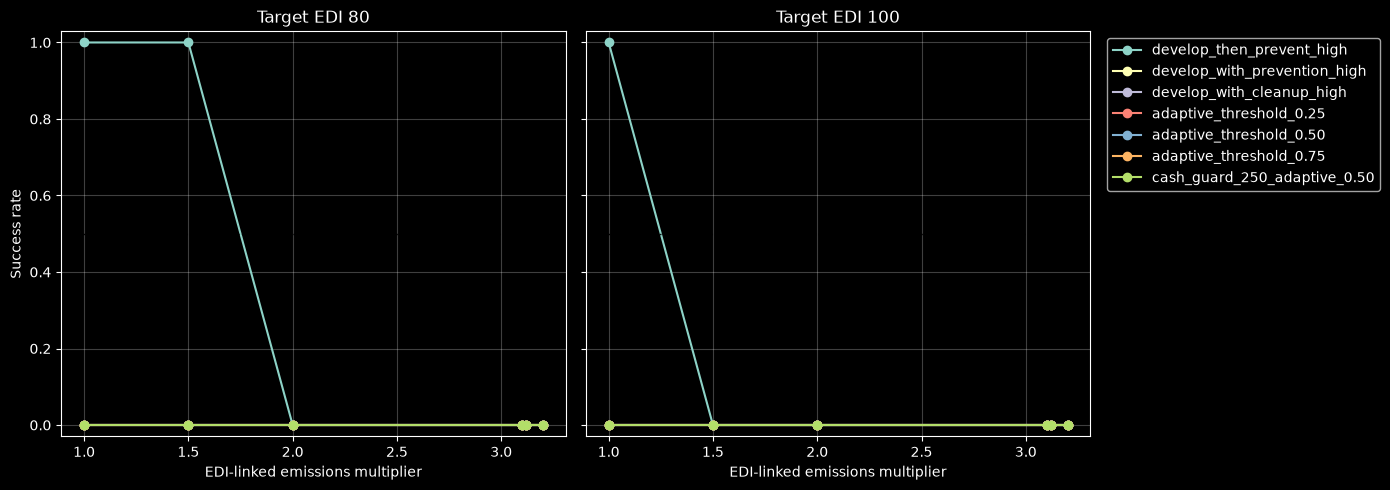

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for axis, target in zip(axes, TARGETS):
    rows = target_summary[target_summary["target"] == target]
    for policy_name in POLICY_RULES:
        policy_rows = rows[rows["policy"] == policy_name].sort_values("emission_multiplier")
        axis.plot(policy_rows["emission_multiplier"], policy_rows["success_rate"], marker="o", label=policy_name)

    axis.axhline(0.5, color="black", linestyle=":", linewidth=1)
    axis.set(xlabel="EDI-linked emissions multiplier", title=f"Target EDI {target}", ylim=(-0.03, 1.03))
    axis.grid(alpha=0.25)

axes[0].set_ylabel("Success rate")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Inspect paired growth trajectories

Choose a target and emissions setting with both successful and unsuccessful outcomes. The notebook matches one of each on the same seed, which gives them identical initial regional currency draws. An unsuccessful run may have crossed a pollution limit or survived without reaching the target; the output labels these cases separately. Their EDI, currency, maximum normalized pollution pressure, and per-step actions show when their paths begin to separate.

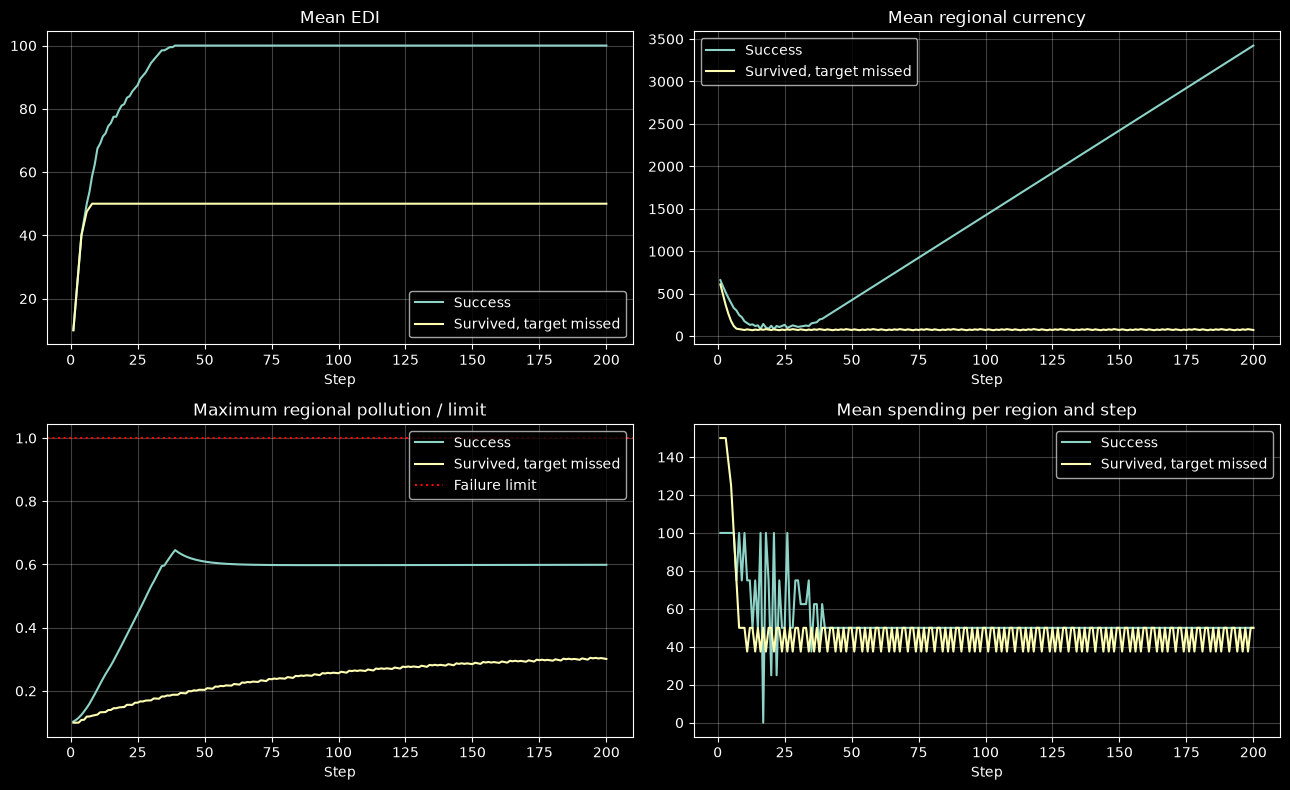

,outcome,policy,target,emission_multiplier,seed,initial_mean_currency,failure_step,failure_pollutants,final_mean_edi,fallback_count
0,Success,develop_then_prevent_high,100,1.0,40000,739.5,NaN,,100.0,36
1,"Survived, target missed",develop_with_prevention_high,100,1.0,40000,739.5,NaN,,50.0,779


In [67]:
mixed_outcomes = target_results.groupby(["target", "emission_multiplier"])["success"].agg(["min", "max"])
mixed_outcomes = mixed_outcomes[(mixed_outcomes["min"] == 0) & (mixed_outcomes["max"] == 1)]

if mixed_outcomes.empty:
    print("No target-multiplier pair has both outcomes. Inspect the success table and select a scenario with mixed policy results.")
else:
    mixed_outcomes = mixed_outcomes.reset_index()
    selected_scenario = mixed_outcomes.sort_values(["target", "emission_multiplier"],ascending=[False, False]).iloc[0]
    selected_target = int(selected_scenario["target"])
    selected_multiplier = float(selected_scenario["emission_multiplier"])
    scenario_rows = target_results[(target_results["target"] == selected_target) & (target_results["emission_multiplier"] == selected_multiplier)]
    success_rows = scenario_rows[scenario_rows["success"]]
    unsuccessful_rows = scenario_rows[~scenario_rows["success"]]

    if success_rows.empty or unsuccessful_rows.empty:
        print("This target-multiplier pair no longer has both successful and unsuccessful runs.")
    else:
        matched_pair = None

        for _, success_row in success_rows.iterrows():
            same_seed_unsuccessful = unsuccessful_rows[unsuccessful_rows["seed"] == success_row["seed"]]
            if not same_seed_unsuccessful.empty:
                matched_pair = (success_row, same_seed_unsuccessful.iloc[0])
                break

        if matched_pair is None:
            success_row = success_rows.iloc[0]
            unsuccessful_row = unsuccessful_rows.iloc[0]
        else:
            success_row, unsuccessful_row = matched_pair

        config = make_experiment_config(selected_multiplier)
        trajectory_cases = []
        failure_label = "Survived, target missed"

        if unsuccessful_row["failed"]:
            failure_label = "Environmental failure"
        case_rows = (("Success", success_row),(failure_label, unsuccessful_row))

        for label, episode_row in case_rows:
            trace_row = run_policy_episode(episode_row["policy"], int(episode_row["seed"]), config, selected_target, save_trace=True)
            trace = pd.DataFrame(trace_row["trajectory"])
            summary = trace.groupby("step").agg(mean_edi=("edi", "mean"), mean_currency=("currency", "mean"), maximum_pressure=("pressure", "max"), mean_spending=("spending", "mean"))
            trajectory_cases.append((label, episode_row, summary))

        fig, axes = plt.subplots(2, 2, figsize=(13, 8))
        for label, episode_row, summary in trajectory_cases:
            axes[0, 0].plot(summary.index, summary["mean_edi"], label=label)
            axes[0, 1].plot(summary.index, summary["mean_currency"], label=label)
            axes[1, 0].plot(summary.index, summary["maximum_pressure"], label=label)
            axes[1, 1].plot(summary.index, summary["mean_spending"], label=label)

        axes[1, 0].axhline(1.0, color="red", linestyle=":", label="Failure limit")
        axes[0, 0].set_title("Mean EDI")
        axes[0, 1].set_title("Mean regional currency")
        axes[1, 0].set_title("Maximum regional pollution / limit")
        axes[1, 1].set_title("Mean spending per region and step")
        for axis in axes.flat:
            axis.set_xlabel("Step")
            axis.grid(alpha=0.25)
            axis.legend()
        plt.tight_layout()
        plt.show()


        rows = []

        for label, episode_row, _ in trajectory_cases:
            row = {
                "outcome": label,
                "policy": episode_row["policy"],
                "target": selected_target,
                "emission_multiplier": selected_multiplier,
                "seed": episode_row["seed"],
                "initial_mean_currency": episode_row["mean_initial_currency"],
                "failure_step": episode_row["failure_step"],
                "failure_pollutants": episode_row["failure_pollutants"],
                "final_mean_edi": episode_row["final_mean_edi"],
                "fallback_count": episode_row["fallback_count"],
            }

            rows.append(row)

        df = pd.DataFrame(rows)
        display(df)

The matched plot is descriptive rather than a policy-effect estimate across all seeds. Check whether cash falls before action fallbacks, whether pressure accelerates as EDI rises, and which pollutant first reaches its failure limit. The action-fraction table above shows whether a policy mostly prevented new emissions, cleaned existing stock, or had to fall back to no mitigation.

## 5. Separate liquidity limits from pollution limits

Repeat a smaller policy comparison at the 3.12 stress multiplier while centering initial currency near 150, 500, and 950 per region. This tests whether high-EDI failures shift when regions start with less or more cash. Each starting-cash range spans 100 currency units and stays within the source configuration's 100 to 1000 bounds. The same 50 seeds are reused for matched policy comparisons.

In [68]:
CASH_CENTERS = (150, 500, 950)
CASH_POLICIES = ("develop_then_prevent_high", "adaptive_threshold_0.50", "cash_guard_250_adaptive_0.50")

cash_rows = []
for center, target, policy_name, seed in product(CASH_CENTERS, TARGETS, CASH_POLICIES, SEEDS):
    starting_cash_range = (max(100, center - 50), min(1000, center + 50))
    config = make_experiment_config(3.12, starting_cash_range=starting_cash_range)
    row = run_policy_episode(policy_name, seed, config, target)
    row["initial_cash_center"] = center
    row["initial_cash_range"] = starting_cash_range
    cash_rows.append(row)

cash_results = pd.DataFrame(cash_rows)
cash_summary = cash_results.groupby(["target", "initial_cash_center", "policy"]).agg(
    episodes=("success", "size"),
    success_rate=("success", "mean"),
    target_reached_rate=("reached_target", "mean"),
    mean_final_edi=("final_mean_edi", "mean"),
    mean_failure_step=("failure_step", "mean"),
    mean_fallback_count=("fallback_count", "mean"),
    mean_final_currency=("final_mean_currency", "mean"),
).reset_index()
display(cash_summary.round(3))

,target,initial_cash_center,policy,episodes,success_rate,target_reached_rate,mean_final_edi,mean_failure_step,mean_fallback_count,mean_final_currency
0,80,150,adaptive_threshold_0.50,50,0.0,0.0,10.000,NaN,797.94,48.715
1,80,150,cash_guard_250_adaptive_0.50,50,0.0,0.0,12.300,NaN,756.10,38.040
2,80,150,develop_then_prevent_high,50,0.0,0.0,74.240,28.22,64.40,102.318
3,80,500,adaptive_threshold_0.50,50,0.0,0.0,37.300,139.74,545.86,65.390
4,80,500,cash_guard_250_adaptive_0.50,50,0.0,0.0,46.475,159.98,164.92,55.465
5,80,500,develop_then_prevent_high,50,0.0,0.0,77.290,20.88,28.94,108.430
6,80,950,adaptive_threshold_0.50,50,0.0,0.0,59.300,168.52,644.46,73.002
7,80,950,cash_guard_250_adaptive_0.50,50,0.0,1.0,80.000,80.70,103.14,74.358
8,80,950,develop_then_prevent_high,50,0.0,1.0,80.000,67.00,0.00,642.965
9,100,150,adaptive_threshold_0.50,50,0.0,0.0,10.000,NaN,797.94,48.715


### What cash sensitivity distinguishes

If extra starting cash raises target attainment and reduces fallback counts, the policy was constrained by the timing of costs during development. If it improves target attainment but failures still occur during maintenance, cash was only part of the problem. If outcomes barely change across these starting balances, inspect emissions and pollutant stocks before changing affordability assumptions.

At target EDI 80 and multiplier 3.12, the development-then-prevention policy's mean final EDI rose from 74.24 at the 150 cash center to 77.29 at 500 and 80 at 950. All 50 runs at the 950 center reached EDI 80, but the policy still failed environmentally before step 200 (mean failure step 67). At the 150 and 500 centers, none reached the target. More starting cash helped with development progress, but it did not make this stress case sustainable.

## 6. Hold EDI fixed with ample currency

This controlled probe starts every region at EDI 80 or 100, gives each region ample currency, and disables further development by using maintenance-only policies. It runs both from zero pollution and from the configured initial stock of 10. Comparing source emissions with the 3.12 stress scenario tests whether pollution can remain below failure limits after development costs and starting-cash constraints are removed.

In [69]:
MAINTENANCE_MULTIPLIERS = (1.0, 3.12)
MAINTENANCE_EDI = (80, 100)
INITIAL_STOCKS = (0.0, 10.0)
UNLIMITED_CURRENCY = 1_000_000

maintenance_rows = []
maintenance_traces = []

for multiplier, edi, initial_stock, policy_name in product(MAINTENANCE_MULTIPLIERS, MAINTENANCE_EDI, INITIAL_STOCKS, MAINTENANCE_RULES):
    config = make_experiment_config(multiplier)
    initial_state = {"edi": edi, "currency": UNLIMITED_CURRENCY, "pollution": initial_stock}
    row = run_policy_episode(policy_name, seed=50_000, config=config, target=edi, initial_state=initial_state, save_trace=True)
    row["emission_multiplier"] = multiplier
    row["initial_pollution"] = initial_stock
    maintenance_rows.append(row)

    for trace_row in row["trajectory"]:
        trace_row["policy"] = policy_name
        trace_row["EDI target"] = edi
        trace_row["emission_multiplier"] = multiplier
        trace_row["initial_pollution"] = initial_stock
        maintenance_traces.append(trace_row)

maintenance_results = pd.DataFrame(maintenance_rows)
maintenance_summary = maintenance_results[["target", "emission_multiplier", "initial_pollution", "policy", "survived", "steps", "failure_step", "failure_pollutants", "peak_pressure", "peak_air", "peak_water", "peak_soil", "peak_noise", "final_mean_currency", "prevention_spending", "cleanup_spending"]]

display(maintenance_summary.round(3))

,target,emission_multiplier,initial_pollution,policy,survived,steps,failure_step,failure_pollutants,peak_pressure,peak_air,peak_water,peak_soil,peak_noise,final_mean_currency,prevention_spending,cleanup_spending
0,80,1.00,0.0,maintain_prevent_high,True,200,NaN,,0.328,3.956,9.364,32.817,1.222,1002000.0,40000.0,0.0
1,80,1.00,0.0,maintain_clean_high,True,200,NaN,,0.000,0.000,0.000,0.000,0.000,996000.0,0.0,64000.0
2,80,1.00,0.0,maintenance_adaptive_0.25,True,200,NaN,,0.251,3.956,9.364,25.057,1.222,1001910.0,39400.0,960.0
3,80,1.00,0.0,maintenance_adaptive_0.50,True,200,NaN,,0.328,3.956,9.364,32.817,1.222,1002000.0,40000.0,0.0
4,80,1.00,0.0,maintenance_adaptive_0.75,True,200,NaN,,0.328,3.956,9.364,32.817,1.222,1002000.0,40000.0,0.0
5,80,1.00,10.0,maintain_prevent_high,True,200,NaN,,0.337,10.000,10.000,33.680,10.000,1002000.0,40000.0,0.0
6,80,1.00,10.0,maintain_clean_high,True,200,NaN,,0.100,10.000,10.000,10.000,10.000,996000.0,0.0,64000.0
7,80,1.00,10.0,maintenance_adaptive_0.25,True,200,NaN,,0.251,10.000,10.000,25.104,10.000,1001880.0,39200.0,1280.0
8,80,1.00,10.0,maintenance_adaptive_0.50,True,200,NaN,,0.337,10.000,10.000,33.680,10.000,1002000.0,40000.0,0.0
9,80,1.00,10.0,maintenance_adaptive_0.75,True,200,NaN,,0.337,10.000,10.000,33.680,10.000,1002000.0,40000.0,0.0


### How to read the maintenance probe

Survival at fixed EDI with ample currency demonstrates that the environment can sustain that EDI under that maintenance policy and emissions setting. If a policy fails even from zero initial pollution, its ongoing prevention or cleanup rule is insufficient there. If it survives from zero stock but fails from stock 10, accumulated pollution and the initial condition matter. Neither result proves that every conceivable action sequence must fail; the probe compares explicit policies and separates environmental pressure from development financing.

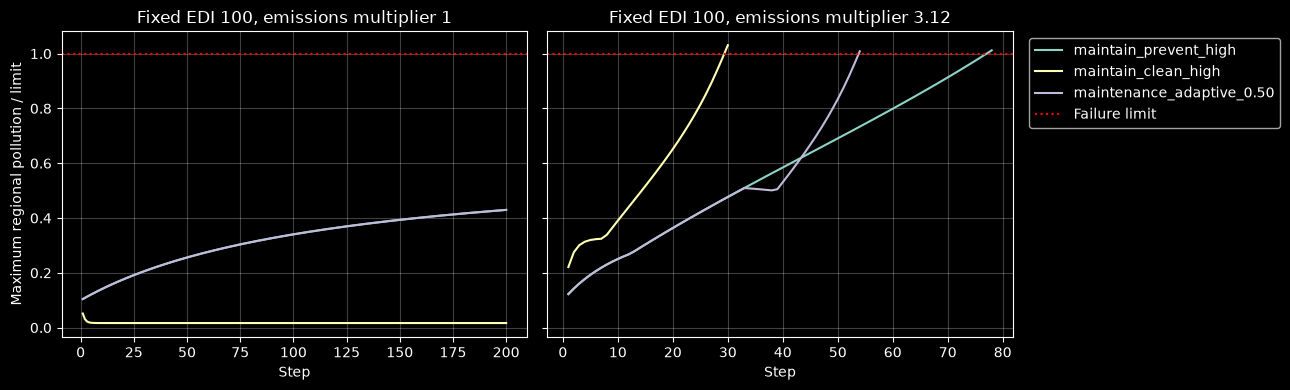

In [70]:
maintenance_trace = pd.DataFrame(maintenance_traces)
target_filter = maintenance_trace["EDI target"] == 100
pollution_filter = maintenance_trace["initial_pollution"] == 10.0
policy_filter = maintenance_trace["policy"].isin(("maintain_prevent_high", "maintain_clean_high", "maintenance_adaptive_0.50"))

selected_trace = maintenance_trace[target_filter & pollution_filter & policy_filter]

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for axis, multiplier in zip(axes, MAINTENANCE_MULTIPLIERS):
    rows = selected_trace[selected_trace["emission_multiplier"] == multiplier]
    for policy_name in rows["policy"].unique():
        policy_rows = rows[rows["policy"] == policy_name].groupby("step").agg(maximum_pressure=("pressure", "max"))
        axis.plot(policy_rows.index, policy_rows["maximum_pressure"], label=policy_name)

    axis.axhline(1.0, color="red", linestyle=":", label="Failure limit")
    axis.set(xlabel="Step", title=f"Fixed EDI 100, emissions multiplier {multiplier:g}")
    axis.grid(alpha=0.25)

axes[0].set_ylabel("Maximum regional pollution / limit")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 7. Decision guide

- **Policy limitation:** At the same emissions multiplier, at least one policy reaches EDI 80 or 100 and survives while another fails. Compare their action traces, cash fallbacks, and spending.
- **Development-finance limitation:** A maintenance policy survives at fixed EDI with ample cash, but the corresponding grow-to-target policy fails or misses the target. Inspect development-plus-mitigation deficits and fallback counts.
- **Environmental pressure under tested policies:** Every tested maintenance policy fails at fixed EDI despite ample cash. This shows the tested controls cannot maintain the target under that emissions scenario; it is still not proof that all possible policies fail.
- **Mixed limitation:** High cash improves target attainment, but even high-cash runs eventually fail at fixed EDI. Both financing during growth and ongoing pollution accumulation matter.

Report per-policy rates beside any pooled rate. The maintenance probe is the strongest evidence in this notebook for distinguishing environment feasibility from the specific development policy, while remaining explicit about the policies tested.